<h1 style="color: magenta; text-align:center">Data Analysis</br>

---

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from src.feature_extraction import FeatureExtractor

In [3]:
data = pd.read_csv("../data/mini_cafa.csv")
data.head()

,accession,sequence,seq_len,labels
0,Q6GZW6,MDTSPYDFLKLYPWLSRGEADKGTLLDAFPGETFEQSLASDVAMRR...,948,GO:0005524;GO:0003677
1,Q6GZV6,MATNYCDEFERNPTRNPRTGRTIKRGGPVFRALERECSDGAARVFP...,851,GO:0005524
2,Q91G63,MKQNLLILLSLLLVVVAIMWWLYEKKKEVPLPPPTPPTPPTPTGVP...,134,GO:0016020
3,Q197B6,MPLSVFAEEFAEKSVKRYIGQGLWLPCNLSDYYYYQEFHDEGGYGS...,335,GO:0005524
4,Q91G50,MDKIEELKIEELKIEIPQRKTKFFHDSENSDKRDEEETLNPTITSK...,123,GO:0016020


In [4]:
data.shape

(15255, 4)

In [5]:
label_counts = data['labels'].str.split(';').explode().value_counts()
print(label_counts)

labels
GO:0005524    4018
GO:0005737    3764
GO:0005829    3463
GO:0005886    2762
GO:0046872    1840
GO:0006633    1773
GO:0005576    1742
GO:0005634    1676
GO:0016020    1571
GO:0008270    1505
GO:0000287    1051
GO:0003989    1008
GO:2001295    1007
GO:0016743     986
GO:0006508     901
GO:0090729     814
GO:0005739     794
GO:0009317     777
GO:0003677     684
GO:0016887     634
Name: count, dtype: int64


In [6]:
# jak widać jest nierównomierny rozkład klas (ale też nie ma tragedii)

C:\Users\posze\AppData\Local\Temp\ipykernel_24608\1084321007.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, palette='viridis')


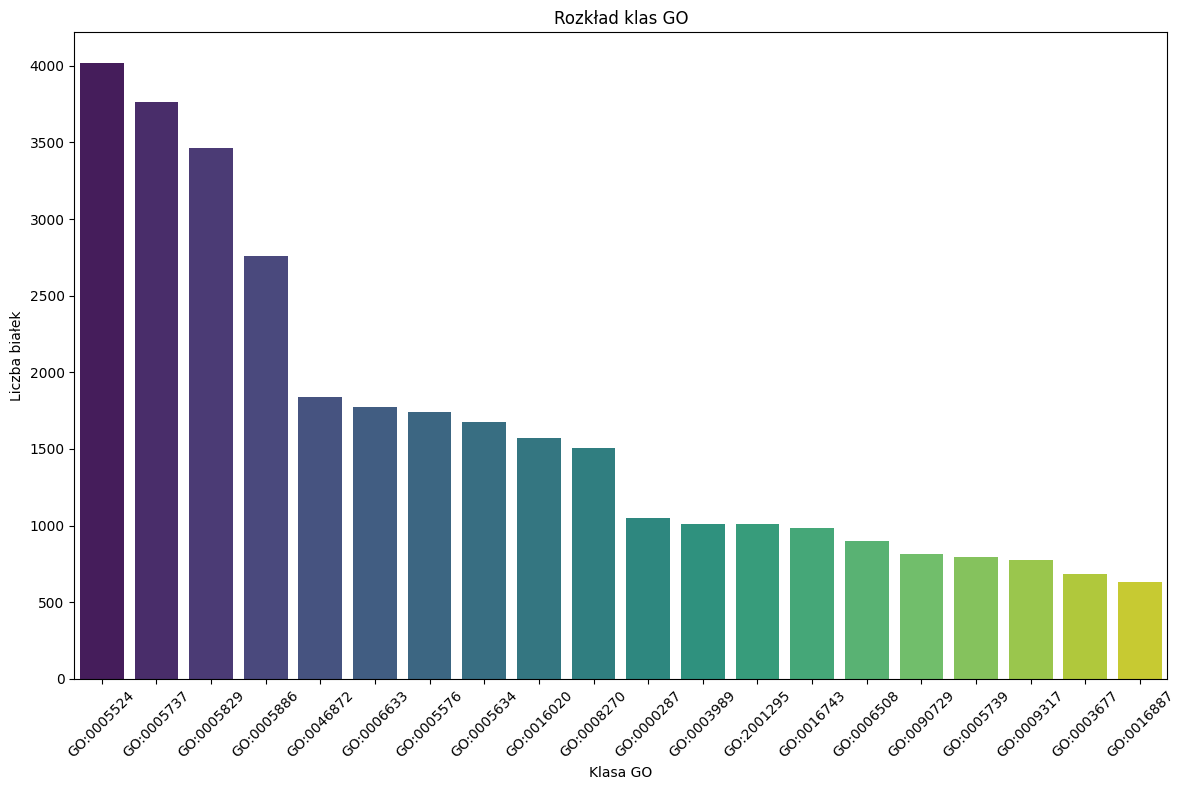

In [7]:
fig = plt.figure(figsize=(12, 8))
sns.barplot(x=label_counts.index, y=label_counts.values, palette='viridis')
plt.xticks(rotation=45)
plt.title('Rozkład klas GO')
plt.xlabel('Klasa GO')
plt.ylabel('Liczba białek')
plt.tight_layout()
plt.show()

# 1. Feature Extraction

In [8]:
feature_extractor = FeatureExtractor(data.to_dict(orient="records"))

In [9]:
features = feature_extractor.extract_features()

In [10]:
features.shape

(15255, 44)

## 2. EDA 

In [11]:
# Cechy które chce sprawdzić: 
# - Długość sekwencji
# - Masa cząsteczkowa
# - Ładunek 
# - Zawartość hydrofobowych aminokwasów

In [12]:
global_features = features[:, -4:]
names = ["Mass", "Charge", "Hydrophobicity", "Length"]

df = pd.DataFrame(global_features, columns=names)
df.describe()

,Mass,Charge,Hydrophobicity,Length
count,15255.000000,15255.000000,15255.000000,15255.000000
mean,128.916916,0.009434,0.414875,441.997650
std,3.287141,0.052537,0.058405,398.684357
min,95.404579,-0.333333,0.066667,4.000000
25%,127.023693,-0.005858,0.392959,232.000000
50%,129.010803,0.012862,0.417565,371.000000
75%,130.908073,0.032495,0.441241,519.000000
max,151.066666,0.400000,0.750000,10227.000000


<Figure size 1200x800 with 0 Axes>

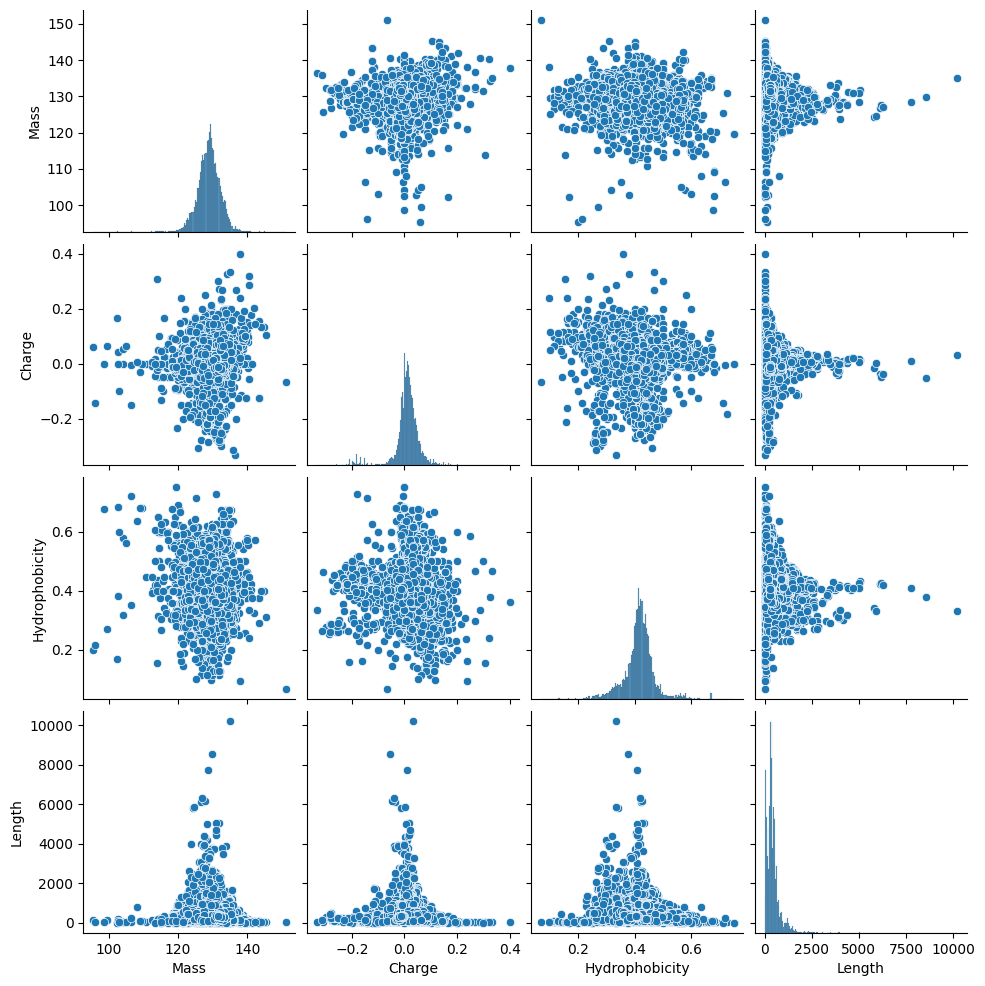

In [13]:
fig = plt.figure(figsize=(12, 8))
sns.pairplot(df)
plt.show()

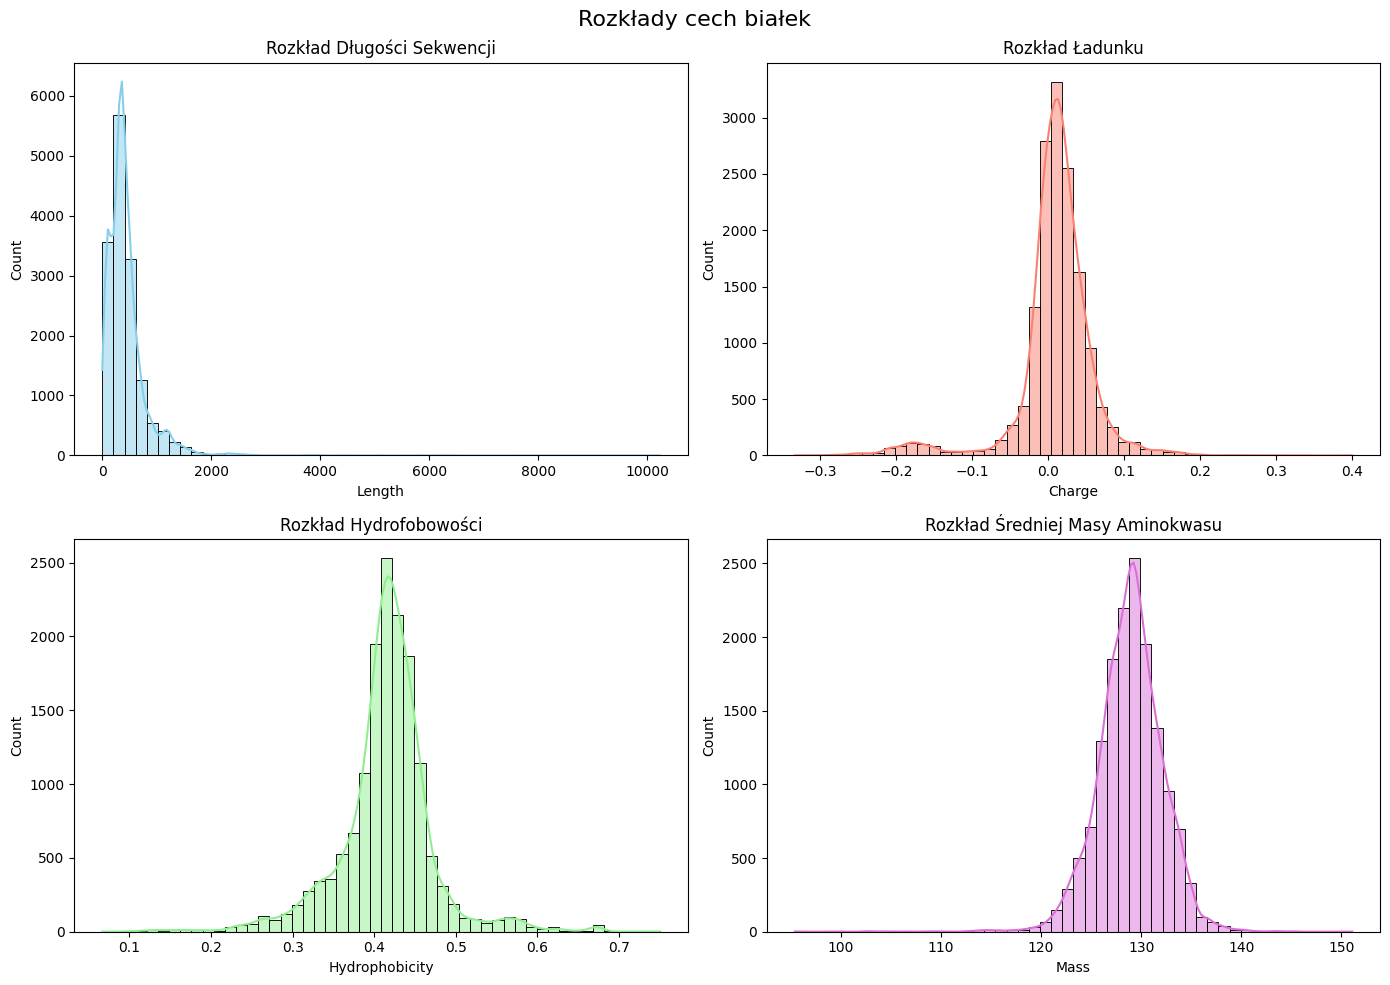

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Rozkłady cech białek', fontsize=16)

sns.histplot(df['Length'], bins=50, kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Rozkład Długości Sekwencji')

sns.histplot(df['Charge'], bins=50, kde=True, ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Rozkład Ładunku')

sns.histplot(df['Hydrophobicity'], bins=50, kde=True, ax=axes[1, 0], color='lightgreen')
axes[1, 0].set_title('Rozkład Hydrofobowości')

sns.histplot(df['Mass'], bins=50, kde=True, ax=axes[1, 1], color='orchid')
axes[1, 1].set_title('Rozkład Średniej Masy Aminokwasu')

plt.tight_layout()
plt.show()

In [15]:
# Trochę wygląda jakby na długość można zastosować logarytm.

---

In [ ]:
names = ["Seq","AA_Frequency","Mass", "Charge", "Hydrophobicity", "Length"]

In [18]:
pd.DataFrame(features, columns=names).to_csv("../data/mini_cafa_features.csv", index=False)

ValueError: Shape of passed values is (15255, 44), indices imply (15255, 6)